# Graph successor task: Vanilla Alignment Search vs. DAS

This notebook uses a **new task**, not the previous carry/addition dataset. It trains a small Transformer from scratch, so no Qwen checkpoint or in-context demonstrations are needed.

## Task

Each example contains the four directed edges of a shuffled Hamiltonian path over nodes `A`–`E`, followed by a query node. The model predicts the next node along the path. For instance, if the path is `C → A → E → B → D`, querying `E` yields `B`.

Matched base/source pairs use the **same graph and same edge ordering** but different query nodes, so the correct one-token answers differ. This is a controlled interchange-intervention setting: patching a source activation into the base run should move the base prediction toward the source answer if the patched state carries query-relevant information.

The task is synthetic and fully reproducible. Both search methods operate on the same trained Transformer and same matched-pair dataset.


In [1]:
import math, random, itertools, copy, time
from collections import defaultdict
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)


device: cuda


## 1. Vocabulary and dataset

Every prompt has the same length and token layout: four shuffled `(source, destination)` edge pairs, then `Q`, then the query node. Targets are one of `A`–`E`. No demonstration examples are placed in the prompt, so there is no in-context prompt variation.

In [2]:
NODES = list("ABCDE")
TOKENS = ["PAD", "Q"] + NODES
stoi = {s:i for i,s in enumerate(TOKENS)}
itos = {i:s for s,i in stoi.items()}
VOCAB = len(TOKENS)
SEQ_LEN = 10  # 8 edge tokens + Q + query node

def make_graph_example(rng):
    path = NODES.copy()
    rng.shuffle(path)
    edges = list(zip(path[:-1], path[1:]))
    rng.shuffle(edges)
    flat = [x for edge in edges for x in edge]
    return path, edges, flat

def prompt_ids(flat_edges, query):
    return [stoi[x] for x in flat_edges] + [stoi["Q"], stoi[query]]

def make_examples(n_graphs, seed):
    rng = random.Random(seed)
    rows = []
    for _ in range(n_graphs):
        path, edges, flat = make_graph_example(rng)
        # Query only nodes with a successor, so target is always a node token.
        for q in path[:-1]:
            target = path[path.index(q)+1]
            rows.append((prompt_ids(flat, q), stoi[target], tuple(flat), q, target, tuple(path)))
    rng.shuffle(rows)
    return rows

train_rows = make_examples(5000, 101)
val_rows = make_examples(600, 202)
test_rows = make_examples(600, 303)
print("train/val/test:", len(train_rows), len(val_rows), len(test_rows))
print("example:", train_rows[0])


train/val/test: 20000 2400 2400
example: ([2, 6, 6, 5, 5, 3, 4, 2, 1, 6], 5, ('A', 'E', 'E', 'D', 'D', 'B', 'C', 'A'), 'E', 'D', ('C', 'A', 'E', 'D', 'B'))


In [3]:
class GraphDataset(Dataset):
    def __init__(self, rows):
        self.rows = rows
    def __len__(self): return len(self.rows)
    def __getitem__(self, i):
        x, y, *_ = self.rows[i]
        return torch.tensor(x, dtype=torch.long), torch.tensor(y, dtype=torch.long)

train_loader = DataLoader(GraphDataset(train_rows), batch_size=256, shuffle=True)
val_loader = DataLoader(GraphDataset(val_rows), batch_size=512)
test_loader = DataLoader(GraphDataset(test_rows), batch_size=512)


## 2. Small Transformer

A bidirectional Transformer encoder reads the complete edge list and query. The output head reads the final query-node position and predicts one node token. We retain intermediate residual-stream activations for interchange interventions.

In [4]:
class TinyGraphTransformer(nn.Module):
    def __init__(self, vocab_size=VOCAB, d_model=64, n_heads=4, n_layers=3, max_len=SEQ_LEN):
        super().__init__()
        self.cfg = type("Cfg", (), {"n_layers": n_layers, "d_model": d_model})()
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Parameter(torch.randn(1, max_len, d_model) * 0.02)
        layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=n_heads, dim_feedforward=4*d_model,
            dropout=0.0, batch_first=True, norm_first=True, activation="gelu"
        )
        self.blocks = nn.ModuleList([copy.deepcopy(layer) for _ in range(n_layers)])
        self.final_norm = nn.LayerNorm(d_model)
        self.unembed = nn.Linear(d_model, vocab_size)
        self.cache = {}
    def forward(self, tokens, cache=False):
        h = self.token_emb(tokens) + self.pos_emb[:, :tokens.shape[1], :]
        saved = []
        for i, block in enumerate(self.blocks):
            h = block(h)
            saved.append(h)
        logits = self.unembed(self.final_norm(h[:, -1, :]))
        if cache:
            self.cache = {i: a for i, a in enumerate(saved)}
            self.cache["embed"] = self.token_emb(tokens) + self.pos_emb[:, :tokens.shape[1], :]
        return logits

model = TinyGraphTransformer().to(device)


In [5]:
def evaluate(model, loader):
    model.eval(); correct=total=0; loss_sum=0.0
    with torch.no_grad():
        for x,y in loader:
            x,y=x.to(device),y.to(device)
            logits=model(x)
            loss_sum += F.cross_entropy(logits,y,reduction="sum").item()
            correct += (logits.argmax(-1)==y).sum().item(); total += y.numel()
    return {"accuracy":correct/total, "loss":loss_sum/total}

opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
best_val = 0
for epoch in range(200):
    model.train()
    for x,y in train_loader:
        x,y=x.to(device),y.to(device)
        opt.zero_grad(set_to_none=True)
        loss=F.cross_entropy(model(x),y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
    val=evaluate(model,val_loader)
    if val["accuracy"] > best_val:
        best_val=val["accuracy"]; best_state=copy.deepcopy(model.state_dict())
    if epoch==0 or (epoch+1)%5==0:
        print(f"epoch {epoch+1:02d} | val acc {val['accuracy']:.3f} | loss {val['loss']:.3f}")
model.load_state_dict(best_state)
print("test:", evaluate(model,test_loader))


epoch 01 | val acc 0.349 | loss 1.356
epoch 05 | val acc 0.350 | loss 1.129
epoch 10 | val acc 0.312 | loss 1.118
epoch 15 | val acc 0.324 | loss 1.106
epoch 20 | val acc 0.335 | loss 1.108
epoch 25 | val acc 0.328 | loss 1.156
epoch 30 | val acc 0.324 | loss 1.115
epoch 35 | val acc 0.336 | loss 1.107
epoch 40 | val acc 0.324 | loss 1.106
epoch 45 | val acc 0.328 | loss 1.108
epoch 50 | val acc 0.324 | loss 1.110
epoch 55 | val acc 0.342 | loss 1.112
epoch 60 | val acc 0.330 | loss 1.112
epoch 65 | val acc 0.320 | loss 1.110
epoch 70 | val acc 0.431 | loss 1.020
epoch 75 | val acc 0.939 | loss 0.155
epoch 80 | val acc 0.995 | loss 0.020
epoch 85 | val acc 0.994 | loss 0.019
epoch 90 | val acc 0.998 | loss 0.005
epoch 95 | val acc 0.997 | loss 0.011
epoch 100 | val acc 0.998 | loss 0.006
epoch 105 | val acc 1.000 | loss 0.000
epoch 110 | val acc 1.000 | loss 0.000
epoch 115 | val acc 1.000 | loss 0.000
epoch 120 | val acc 1.000 | loss 0.000
epoch 125 | val acc 1.000 | loss 0.000
epoch 

## 3. Build matched base/source pairs

A pair shares the exact graph and edge order, but uses two distinct query nodes. We keep only pairs for which the model correctly predicts both answers and the gold answers differ. Search and validation use disjoint graph seeds.

In [6]:
def rows_to_prompt(row):
    x,y,flat,q,target,path = row
    return torch.tensor(x, dtype=torch.long), y

def build_pairs(rows, max_pairs=1000):
    # Group rows by exact edge sequence. Query/target differ within each graph.
    groups=defaultdict(list)
    for row in rows: groups[row[2]].append(row)
    pairs=[]
    model.eval()
    with torch.no_grad():
        for flat, group in groups.items():
            if len(group)<2: continue
            # Pair queries in the same graph; only retain clean-correct pairs.
            for a,b in itertools.combinations(group,2):
                if a[3]==b[3] or a[4]==b[4]: continue
                xa=torch.tensor(a[0],device=device).unsqueeze(0)
                xb=torch.tensor(b[0],device=device).unsqueeze(0)
                ya,yb=a[1],b[1]
                if model(xa).argmax(-1).item()==ya and model(xb).argmax(-1).item()==yb:
                    pairs.append({"base":xa[0].cpu(),"source":xb[0].cpu(),
                                  "base_y":ya,"source_y":yb,
                                  "base_query":a[3],"source_query":b[3],
                                  "flat":flat,"path":a[5]})
                    if len(pairs)>=max_pairs: return pairs
    return pairs

search_pairs=build_pairs(val_rows, max_pairs=500)
heldout_pairs=build_pairs(test_rows, max_pairs=300)
print("search pairs:",len(search_pairs),"held-out pairs:",len(heldout_pairs))
assert search_pairs and heldout_pairs, "Model accuracy too low for clean matched-pair search; train longer or increase data."


search pairs: 500 held-out pairs: 300


In [7]:
def decode_prompt(x):
    return " ".join(itos[int(t)] for t in x)
p=search_pairs[0]
print("BASE:  ",decode_prompt(p["base"]),"->",itos[p["base_y"]])
print("SOURCE:",decode_prompt(p["source"]),"->",itos[p["source_y"]])
assert p["base_y"] != p["source_y"]


BASE:   D E C D A B E A Q D -> E
SOURCE: D E C D A B E A Q A -> B


## 4. Interchange intervention machinery

For a selected set of `(layer, position)` nodes, replace the base activation with the source activation at those locations. The interchange score is the fraction of pairs where the intervened base prediction equals the source answer. We also report the unpatched base accuracy and clean source accuracy.

For vanilla alignment search, a continuous mask is optimized over candidate nodes and thresholded for evaluation. For DAS, we learn a one-dimensional orthogonal subspace (a unit direction) at each candidate node and transfer only the source-base activation difference projected onto that direction. This is a small, explicit DAS-style subspace intervention rather than a call to a third-party DAS package.

In [8]:
@torch.no_grad()
def get_activations(x):
    model.eval()
    _ = model(x.to(device), cache=True)
    return {k:v.detach() for k,v in model.cache.items() if isinstance(k,int)}

# Candidate nodes are query-token positions across all layers.
# Query node is at sequence position 9 (0-indexed); expand to all positions for discovery.
CANDIDATES = [(layer,pos) for layer in range(model.cfg.n_layers) for pos in range(8,10)]
print("candidate nodes:",len(CANDIDATES),CANDIDATES)


candidate nodes: 6 [(0, 8), (0, 9), (1, 8), (1, 9), (2, 8), (2, 9)]


In [9]:
def batch_pair_acts(pairs):
    xb=torch.stack([p["base"] for p in pairs]).to(device)
    xs=torch.stack([p["source"] for p in pairs]).to(device)
    ab=get_activations(xb); ass=get_activations(xs)
    yb=torch.tensor([p["base_y"] for p in pairs],device=device)
    ys=torch.tensor([p["source_y"] for p in pairs],device=device)
    return xb,xs,ab,ass,yb,ys

def patched_logits(xb, ab, ass, selected, alpha=None):
    # selected is [(layer,pos)] and alpha optional interpolation weights per node.
    _ = model(xb, cache=True)
    h=model.cache.get("unused")
    # Re-run blocks with cached source/base residual activations and apply patches after chosen blocks.
    # Since block outputs are the cached layer activations, interventions at layer l are applied
    # after block l and subsequent blocks are recomputed.
    h=model.token_emb(xb)+model.pos_emb[:,:xb.shape[1],:]
    for l,block in enumerate(model.blocks):
        h=block(h)
        for j,node in enumerate(selected):
            ll,pos=node
            if ll==l:
                src=ass[ll][:,pos,:]
                if alpha is None:
                    h[:,pos,:]=src
                else:
                    h[:,pos,:]=h[:,pos,:] + alpha[j]*(src-h[:,pos,:])
    return model.unembed(model.final_norm(h[:,-1,:]))

def iia_score(pairs, selected):
    xb,xs,ab,ass,yb,ys=batch_pair_acts(pairs)
    with torch.no_grad():
        logits=patched_logits(xb,ab,ass,selected)
        return (logits.argmax(-1)==ys).float().mean().item()

def clean_scores(pairs):
    xb,xs,ab,ass,yb,ys=batch_pair_acts(pairs)
    with torch.no_grad():
        base=(model(xb).argmax(-1)==yb).float().mean().item()
        source=(model(xs).argmax(-1)==ys).float().mean().item()
    return base,source

print("clean search-pair accuracies:",clean_scores(search_pairs))


clean search-pair accuracies: (1.0, 1.0)


## 5. Vanilla alignment search (mask optimization)

Optimize a sigmoid mask over candidate nodes. A sparse penalty encourages selecting few nodes. The final selected nodes are evaluated with hard interchange patches.

In [10]:
def vanilla_alignment_search(pairs, steps=250, lr=0.05, sparsity=0.07, batch_size=64):
    # Optimize soft selection over candidate layer-position sites.
    xb,xs,ab,ass,yb,ys=batch_pair_acts(pairs)
    alpha_logits=nn.Parameter(torch.full((len(CANDIDATES),),-2.0,device=device))
    opt_mask=torch.optim.Adam([alpha_logits],lr=lr)
    for step in range(steps):
        idx=torch.randint(0,len(pairs),(min(batch_size,len(pairs)),),device=device)
        # Make a differentiable intervention. Each selected node's activation is interpolated.
        logits=patched_logits(xb[idx],{k:v[idx] for k,v in ab.items()},
                              {k:v[idx] for k,v in ass.items()},CANDIDATES,
                              alpha=torch.sigmoid(alpha_logits))
        loss=F.cross_entropy(logits,ys[idx]) + sparsity*torch.sigmoid(alpha_logits).sum()
        opt_mask.zero_grad(); loss.backward(); opt_mask.step()
        if (step+1)%50==0:
            print(f"step {step+1}: loss={loss.item():.3f}, mean mask={torch.sigmoid(alpha_logits).mean().item():.3f}")
    probs=torch.sigmoid(alpha_logits).detach()
    # Threshold with a fallback to the highest-scoring node.
    chosen=[CANDIDATES[i] for i in range(len(CANDIDATES)) if probs[i]>.5]
    if not chosen: chosen=[CANDIDATES[int(probs.argmax())]]
    return chosen, probs.cpu().numpy()

vanilla_nodes, vanilla_mask = vanilla_alignment_search(search_pairs)
print("vanilla nodes:",vanilla_nodes)
print("vanilla train IIA:",iia_score(search_pairs,vanilla_nodes))
print("vanilla held-out IIA:",iia_score(heldout_pairs,vanilla_nodes))


step 50: loss=0.190, mean mask=0.220
step 100: loss=0.106, mean mask=0.230
step 150: loss=0.112, mean mask=0.233
step 200: loss=0.110, mean mask=0.237
step 250: loss=0.103, mean mask=0.239
vanilla nodes: [(2, 9)]
vanilla train IIA: 1.0
vanilla held-out IIA: 1.0


## 6. DAS-style subspace alignment search

For each candidate site, learn a unit vector `v`. The intervention replaces only the component of the source-base activation difference along `v`:

`h_base' = h_base + (vᵀ(h_source − h_base)) v`

This is a rank-1 interchange intervention. We optimize a soft node mask and the directions jointly. The orthogonality constraint for each direction is enforced by normalization; with rank one, that means `||v||₂ = 1`. This is a compact DAS-style implementation designed for the toy model and should not be confused with a faithful reproduction of every detail of a published DAS implementation.

In [11]:
def das_alignment_search(pairs, steps=1000, lr=0.03, sparsity=0.1, batch_size=64):
    xb,xs,ab,ass,yb,ys=batch_pair_acts(pairs)
    d=model.cfg.d_model
    dirs=nn.Parameter(torch.randn(len(CANDIDATES),d,device=device)*0.1)
    mask_logits=nn.Parameter(torch.full((len(CANDIDATES),),-2.0,device=device))
    opt_das=torch.optim.Adam([dirs,mask_logits],lr=lr)
    for step in range(steps):
        idx=torch.randint(0,len(pairs),(min(batch_size,len(pairs)),),device=device)
        # Construct normalized directions and perform projected interchange at all candidate sites.
        unit=F.normalize(dirs,dim=-1)
        # Recompute from embeddings, applying projections after each block.
        x=xb[idx]; src_acts={k:v[idx] for k,v in ass.items()}
        h=model.token_emb(x)+model.pos_emb[:,:x.shape[1],:]
        mask=torch.sigmoid(mask_logits)
        for l,block in enumerate(model.blocks):
            h=block(h)
            for j,(ll,pos) in enumerate(CANDIDATES):
                if ll==l:
                    # Source activation difference from cached clean source run.
                    delta=src_acts[l][:,pos,:] - ab[l][idx,pos,:]
                    v=unit[j]
                    projected=(delta@v).unsqueeze(-1)*v.unsqueeze(0)
                    h[:,pos,:]=h[:,pos,:] + mask[j]*projected
        logits=model.unembed(model.final_norm(h[:,-1,:]))
        loss=F.cross_entropy(logits,ys[idx]) + sparsity*mask.sum()
        opt_das.zero_grad(); loss.backward(); opt_das.step()
        if (step+1)%60==0:
            print(f"step {step+1}: loss={loss.item():.3f}, mean mask={mask.mean().item():.3f}")
    probs=torch.sigmoid(mask_logits).detach()
    chosen=[CANDIDATES[i] for i in range(len(CANDIDATES)) if probs[i]>.5]
    if not chosen: chosen=[CANDIDATES[int(probs.argmax())]]
    return chosen, probs.cpu().numpy(), F.normalize(dirs.detach(),dim=-1)

das_nodes,das_mask,das_dirs=das_alignment_search(search_pairs)
print("DAS nodes:",das_nodes)
print("DAS train IIA:",iia_score(heldout_pairs if False else search_pairs,das_nodes))


step 60: loss=4.086, mean mask=0.268
step 120: loss=2.030, mean mask=0.382
step 180: loss=2.204, mean mask=0.415
step 240: loss=2.156, mean mask=0.433
step 300: loss=2.423, mean mask=0.446
step 360: loss=2.917, mean mask=0.456
step 420: loss=0.975, mean mask=0.465
step 480: loss=1.423, mean mask=0.471
step 540: loss=1.751, mean mask=0.475
step 600: loss=1.517, mean mask=0.478
step 660: loss=1.801, mean mask=0.481
step 720: loss=1.379, mean mask=0.483
step 780: loss=1.776, mean mask=0.485
step 840: loss=1.365, mean mask=0.486
step 900: loss=1.949, mean mask=0.488
step 960: loss=2.222, mean mask=0.489
DAS nodes: [(0, 9), (1, 9), (2, 9)]
DAS train IIA: 1.0


## 7. Validation suite

Compare clean performance, hard intervention, random-node controls, and leave-one-out ablations on held-out pairs. The validation metrics use the same intervention operator for both selected node sets; DAS's learned directions are additionally evaluated in the next cell.

In [12]:
def random_control(pairs, n_selected, trials=30, seed=900):
    rng=random.Random(seed); scores=[]
    for _ in range(trials):
        chosen=rng.sample(CANDIDATES,min(n_selected,len(CANDIDATES)))
        scores.append(iia_score(pairs,chosen))
    return float(np.mean(scores)),float(np.std(scores)),scores

def loo_scores(pairs, selected):
    if len(selected)<=1: return {}
    return {str(node):iia_score(pairs,[n for n in selected if n!=node]) for node in selected}

base_acc,source_acc=clean_scores(heldout_pairs)
print(f"held-out clean base={base_acc:.3f}, source={source_acc:.3f}")
for name,nodes in [("vanilla",vanilla_nodes),("DAS selected sites (full activation patch)",das_nodes)]:
    score=iia_score(heldout_pairs,nodes)
    rmean,rstd,_=random_control(heldout_pairs,len(nodes))
    print(f"{name}: held-out IIA={score:.3f}; random mean={rmean:.3f} ± {rstd:.3f}; nodes={nodes}")
    print("leave-one-out:",loo_scores(heldout_pairs,nodes))


held-out clean base=1.000, source=1.000
vanilla: held-out IIA=1.000; random mean=0.431 ± 0.493; nodes=[(2, 9)]
leave-one-out: {}
DAS selected sites (full activation patch): held-out IIA=1.000; random mean=0.896 ± 0.299; nodes=[(0, 9), (1, 9), (2, 9)]
leave-one-out: {'(0, 9)': 1.0, '(1, 9)': 1.0, '(2, 9)': 0.996666669845581}


In [13]:
def das_projected_iia_score(pairs, selected, directions):
    # Evaluate the learned DAS directions only at the selected sites.
    xb,xs,ab,ass,yb,ys=batch_pair_acts(pairs)
    chosen_idx=[CANDIDATES.index(n) for n in selected]
    _ = model(xb,cache=True)
    h=model.token_emb(xb)+model.pos_emb[:,:xb.shape[1],:]
    for l,block in enumerate(model.blocks):
        h=block(h)
        for node,j in zip(selected,chosen_idx):
            ll,pos=node
            if ll==l:
                delta=ass[l][:,pos,:]-ab[l][:,pos,:]
                v=F.normalize(directions[j],dim=-1)
                h[:,pos,:]=h[:,pos,:]+(delta@v).unsqueeze(-1)*v.unsqueeze(0)
    logits=model.unembed(model.final_norm(h[:,-1,:]))
    return (logits.argmax(-1)==ys).float().mean().item()

print("DAS projected held-out IIA:",das_projected_iia_score(heldout_pairs,das_nodes,das_dirs))


DAS projected held-out IIA: 0.5600000023841858


## 8. Interpretation checklist

A convincing result should satisfy all of the following:

- The Transformer has strong held-out task accuracy.
- Base/source pairs have identical edge tokens and different query nodes/targets.
- The clean base and source answers are correct before intervention.
- The learned intervention moves the base output to the source answer on held-out graphs.
- Learned nodes beat random-node controls.
- Leave-one-out ablation reduces the score for at least some selected nodes.
- DAS projected interventions work, not only full activation patching.

If the model's task accuracy is weak or the filtered pair count is small, do not interpret the search results. Increase training data/epochs or adjust model size first. Because this is a toy Transformer trained from scratch, its discovered nodes need not match the nodes found in Qwen or in a real language model.

## 9. Iterative alignment search with exclusion

This experiment repeatedly runs alignment search on the **remaining candidate sites**. After each round, every site selected in that round is excluded from later rounds. Vanilla and DAS maintain separate exclusion sets.

- `N_ROUNDS` controls the maximum number of rounds.
- The existing candidate universe is preserved. In this notebook it contains six sites, so the process stops once all sites have been excluded.
- The plots compare held-out IIA across rounds, selected-node counts, and a random-site baseline sampled from the *same restricted domain* available in that round.
- DAS is evaluated both with full activation replacement and with its learned projected directions. These are different intervention operators and should not be conflated.


vanilla | round 1 | candidates=[(0, 8), (0, 9), (1, 8), (1, 9), (2, 8), (2, 9)]
step 50: loss=0.185, mean mask=0.220
step 100: loss=0.127, mean mask=0.229
step 150: loss=0.113, mean mask=0.233
step 200: loss=0.137, mean mask=0.238
step 250: loss=0.131, mean mask=0.241
selected=[(2, 9)] | held-out full-patch IIA=1.000 | random=0.464±0.497

vanilla | round 2 | candidates=[(0, 8), (0, 9), (1, 8), (1, 9), (2, 8)]
step 50: loss=0.158, mean mask=0.227
step 100: loss=0.112, mean mask=0.246
step 150: loss=0.104, mean mask=0.253
step 200: loss=0.098, mean mask=0.259
step 250: loss=0.104, mean mask=0.261
selected=[(0, 9), (1, 9)] | held-out full-patch IIA=0.997 | random=0.729±0.439

vanilla | round 3 | candidates=[(0, 8), (1, 8), (2, 8)]
step 50: loss=14.653, mean mask=0.028
step 100: loss=14.808, mean mask=0.012
step 150: loss=13.989, mean mask=0.006
step 200: loss=15.014, mean mask=0.004
step 250: loss=14.530, mean mask=0.003
selected=[(0, 8)] | held-out full-patch IIA=0.000 | random=0.000±0.

,method,round,n_candidates_before,selected_nodes,n_selected,train_iia,heldout_iia,projected_heldout_iia,random_iia_mean,random_iia_std,excluded_after_round
0,vanilla,1,6,"[(2, 9)]",1,1.000,1.000000,NaN,0.464444,0.496521,"[(2, 9)]"
1,vanilla,2,5,"[(0, 9), (1, 9)]",2,0.998,0.996667,NaN,0.728556,0.439345,"[(0, 9), (1, 9), (2, 9)]"
2,vanilla,3,3,"[(0, 8)]",1,0.000,0.000000,NaN,0.000000,0.000000,"[(0, 8), (0, 9), (1, 9), (2, 9)]"
3,vanilla,4,2,"[(2, 8)]",1,0.000,0.000000,NaN,0.000000,0.000000,"[(0, 8), (0, 9), (1, 9), (2, 8), (2, 9)]"
4,vanilla,5,1,"[(1, 8)]",1,0.000,0.000000,NaN,0.000000,0.000000,"[(0, 8), (0, 9), (1, 8), (1, 9), (2, 8), (2, 9)]"
5,das,1,6,"[(0, 9), (1, 9), (2, 9)]",3,1.000,1.000000,0.586667,0.895778,0.298645,"[(0, 9), (1, 9), (2, 9)]"
6,das,2,3,"[(0, 8)]",1,0.000,0.000000,0.000000,0.000000,0.000000,"[(0, 8), (0, 9), (1, 9), (2, 9)]"
7,das,3,2,"[(1, 8)]",1,0.000,0.000000,0.000000,0.000000,0.000000,"[(0, 8), (0, 9), (1, 8), (1, 9), (2, 9)]"
8,das,4,1,"[(2, 8)]",1,0.000,0.000000,0.000000,0.000000,0.000000,"[(0, 8), (0, 9), (1, 8), (1, 9), (2, 8), (2, 9)]"


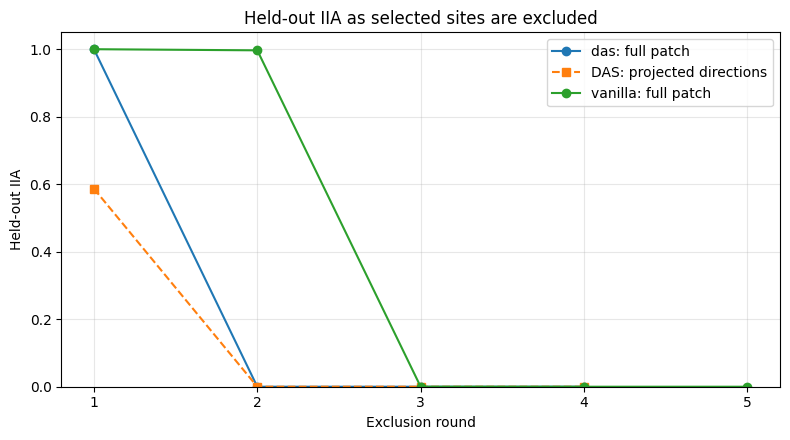

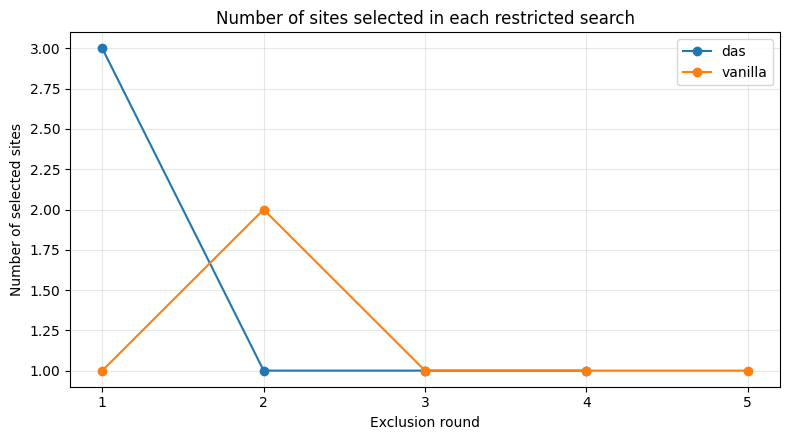

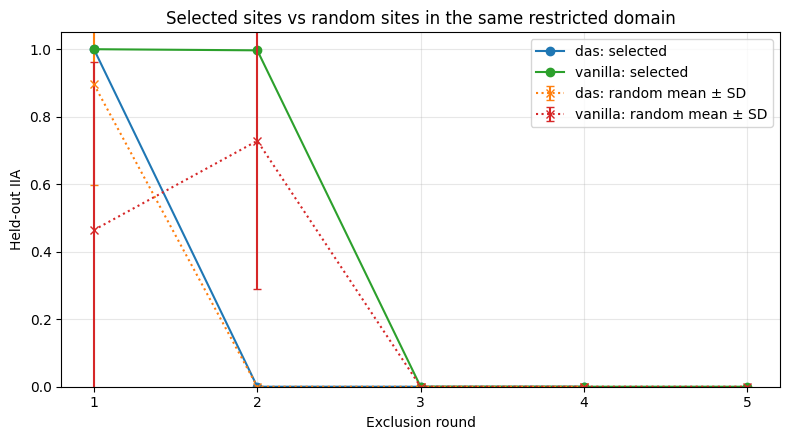

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import random
import numpy as np
import torch

# User controls
N_ROUNDS = 6
ITER_VANILLA_STEPS = 250
ITER_DAS_STEPS = 1000
ITER_RANDOM_TRIALS = 30
ITER_SEED = 2026

# Freeze the original candidate universe so exclusion is explicit and reproducible.
ALL_SEARCH_NODES = list(CANDIDATES)

def iterative_exclusion_search(method, max_rounds=N_ROUNDS):
    """
    Repeatedly search the currently available sites, then exclude all sites
    selected in that round. The candidate domain is restricted independently
    for vanilla and DAS.
    """
    global CANDIDATES
    excluded = set()
    rows = []
    round_details = []
    original_candidates = CANDIDATES.copy()

    try:
        for round_idx in range(1, max_rounds + 1):
            remaining = [node for node in ALL_SEARCH_NODES if node not in excluded]
            if not remaining:
                print(f"{method}: stopping before round {round_idx}; no candidate sites remain.")
                break

            # Existing search functions use the global CANDIDATES variable.
            CANDIDATES = remaining
            seed = ITER_SEED + round_idx
            random.seed(seed)
            np.random.seed(seed)
            torch.manual_seed(seed)
            if torch.cuda.is_available():
                torch.cuda.manual_seed_all(seed)

            print(f"\n{method} | round {round_idx} | candidates={remaining}")

            if method == "vanilla":
                selected, mask_probs = vanilla_alignment_search(
                    search_pairs, steps=ITER_VANILLA_STEPS
                )
                heldout_iia = iia_score(heldout_pairs, selected)
                train_iia = iia_score(search_pairs, selected)
                projected_iia = np.nan
                # Random sites are drawn only from the current restricted domain.
                rmean, rstd, rscores = random_control(
                    heldout_pairs, len(selected),
                    trials=ITER_RANDOM_TRIALS, seed=seed
                )
                details = {
                    "selected": selected,
                    "mask_probs": mask_probs,
                    "directions": None,
                    "random_scores": rscores,
                }

            elif method == "das":
                selected, mask_probs, directions = das_alignment_search(
                    search_pairs, steps=ITER_DAS_STEPS
                )
                # Full replacement measures site sufficiency, not DAS direction quality.
                heldout_iia = iia_score(heldout_pairs, selected)
                train_iia = iia_score(search_pairs, selected)
                # Evaluate learned projected directions while CANDIDATES still matches
                # the candidate indexing used to train those directions.
                projected_iia = das_projected_iia_score(
                    heldout_pairs, selected, directions
                )
                rmean, rstd, rscores = random_control(
                    heldout_pairs, len(selected),
                    trials=ITER_RANDOM_TRIALS, seed=seed
                )
                details = {
                    "selected": selected,
                    "mask_probs": mask_probs,
                    "directions": directions.detach().cpu(),
                    "random_scores": rscores,
                }
            else:
                raise ValueError("method must be 'vanilla' or 'das'")

            rows.append({
                "method": method,
                "round": round_idx,
                "n_candidates_before": len(remaining),
                "selected_nodes": str(selected),
                "n_selected": len(selected),
                "train_iia": train_iia,
                "heldout_iia": heldout_iia,
                "projected_heldout_iia": projected_iia,
                "random_iia_mean": rmean,
                "random_iia_std": rstd,
                "excluded_after_round": str(sorted(excluded.union(selected))),
            })
            round_details.append(details)

            print(
                f"selected={selected} | held-out full-patch IIA={heldout_iia:.3f} | "
                f"random={rmean:.3f}±{rstd:.3f}"
                + (f" | projected DAS IIA={projected_iia:.3f}" if method == "das" else "")
            )

            # Critical step: never allow any site selected this round to be selected again.
            excluded.update(selected)

    finally:
        CANDIDATES = original_candidates

    return pd.DataFrame(rows), round_details

vanilla_iter_df, vanilla_iter_details = iterative_exclusion_search("vanilla")
das_iter_df, das_iter_details = iterative_exclusion_search("das")

iterative_results = pd.concat([vanilla_iter_df, das_iter_df], ignore_index=True)
display(iterative_results)

# Plot 1: held-out IIA by round.
fig, ax = plt.subplots(figsize=(8, 4.5))
for method, frame in iterative_results.groupby("method"):
    ax.plot(frame["round"], frame["heldout_iia"], marker="o", label=f"{method}: full patch")
    if method == "das":
        ax.plot(frame["round"], frame["projected_heldout_iia"],
                marker="s", linestyle="--", label="DAS: projected directions")
ax.set_xlabel("Exclusion round")
ax.set_ylabel("Held-out IIA")
ax.set_ylim(0, 1.05)
ax.set_xticks(sorted(iterative_results["round"].unique()))
ax.set_title("Held-out IIA as selected sites are excluded")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Plot 2: selected node count per round.
fig, ax = plt.subplots(figsize=(8, 4.5))
for method, frame in iterative_results.groupby("method"):
    ax.plot(frame["round"], frame["n_selected"], marker="o", label=method)
ax.set_xlabel("Exclusion round")
ax.set_ylabel("Number of selected sites")
ax.set_xticks(sorted(iterative_results["round"].unique()))
ax.set_title("Number of sites selected in each restricted search")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Plot 3: selected-site IIA versus random baseline from the same restricted domain.
fig, ax = plt.subplots(figsize=(8, 4.5))
for method, frame in iterative_results.groupby("method"):
    ax.plot(frame["round"], frame["heldout_iia"], marker="o", label=f"{method}: selected")
    ax.errorbar(
        frame["round"], frame["random_iia_mean"],
        yerr=frame["random_iia_std"], marker="x", linestyle=":",
        capsize=3, label=f"{method}: random mean ± SD"
    )
ax.set_xlabel("Exclusion round")
ax.set_ylabel("Held-out IIA")
ax.set_ylim(0, 1.05)
ax.set_xticks(sorted(iterative_results["round"].unique()))
ax.set_title("Selected sites vs random sites in the same restricted domain")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 10. Follow-up: ablations and multi-seed robustness

The iterative exclusion experiment suggests that query-token sites are useful, but it does not establish whether individual sites are sufficient or whether the search is stable across random initializations. This section adds:

1. **Single-site and pairwise ablations** of the query-token sites `(0, 9)`, `(1, 9)`, and `(2, 9)`, plus the three-site combination.
2. **Matched full-patch vs. projected-DAS evaluation** for those exact site combinations.
3. **Multi-seed alignment search** for vanilla and DAS over the original candidate set, recording selected sites, held-out IIA, projected DAS IIA, and random full-patching controls.
4. **Plots** for the ablation matrix, multi-seed IIA distributions, and site-selection frequency.

Interpretation caveat: ablation results describe sufficiency under this intervention, not proof that a site is the model's unique internal mechanism. The random baseline below is explicitly a full-activation-patching baseline; it is not a projected-direction baseline for DAS.

Single-site and pairwise ablations (full activation replacement):


,sites,n_sites,full_patch_heldout_iia,random_full_patch_mean,random_full_patch_std
0,"[(0, 9)]",1,0.990000,0.597778,0.488095
1,"[(1, 9)]",1,0.993333,0.597778,0.488095
2,"[(2, 9)]",1,1.000000,0.597778,0.488095
3,"[(0, 9), (1, 9)]",2,0.996667,0.796222,0.398127
4,"[(0, 9), (2, 9)]",2,1.000000,0.796222,0.398127
5,"[(1, 9), (2, 9)]",2,1.000000,0.796222,0.398127
6,"[(0, 9), (1, 9), (2, 9)]",3,1.000000,0.929222,0.248390


Added projected-DAS scores using the previously trained das_dirs.


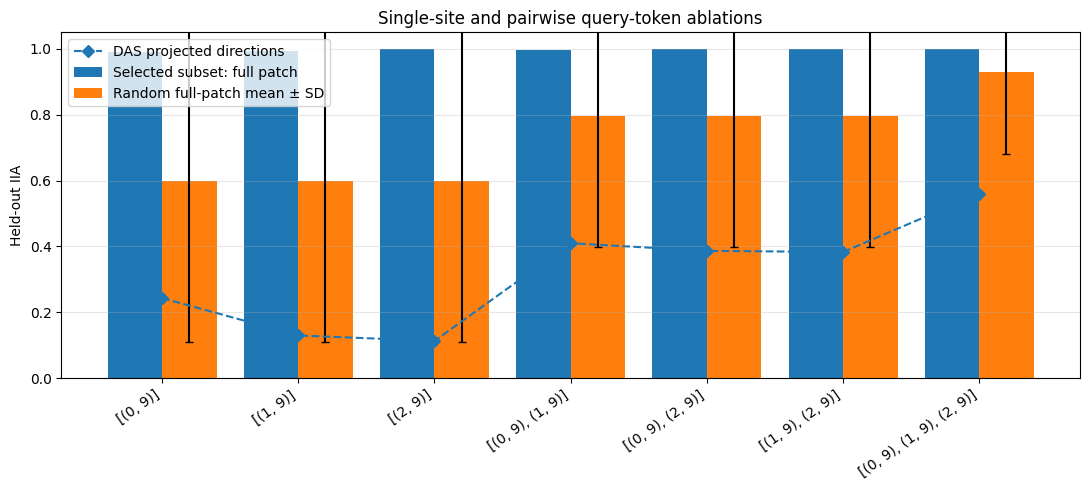


=== Multi-seed search, seed=11 ===
step 50: loss=0.135, mean mask=0.221
step 100: loss=0.108, mean mask=0.231
step 150: loss=0.105, mean mask=0.236
step 200: loss=0.120, mean mask=0.239
step 250: loss=0.105, mean mask=0.240
vanilla: sites=[(2, 9)]; held-out IIA=1.000; random=0.432±0.494
step 60: loss=6.350, mean mask=0.249
step 120: loss=2.665, mean mask=0.374
step 180: loss=1.997, mean mask=0.418
step 240: loss=1.293, mean mask=0.437
step 300: loss=1.447, mean mask=0.451
step 360: loss=1.726, mean mask=0.461
step 420: loss=1.981, mean mask=0.467
step 480: loss=1.798, mean mask=0.472
step 540: loss=0.852, mean mask=0.476
step 600: loss=1.929, mean mask=0.479
step 660: loss=2.263, mean mask=0.481
step 720: loss=1.288, mean mask=0.483
step 780: loss=1.477, mean mask=0.485
step 840: loss=1.026, mean mask=0.486
step 900: loss=1.443, mean mask=0.488
step 960: loss=2.137, mean mask=0.489
DAS: sites=[(0, 9), (1, 9), (2, 9)]; full-patch IIA=1.000; projected IIA=0.563; random=0.996±0.005

=== 

,method,seed,selected_sites,n_selected,heldout_full_patch_iia,heldout_projected_iia,random_full_patch_mean,random_full_patch_std
0,vanilla,11,"[(2, 9)]",1,1.0,NaN,0.431889,0.493892
1,DAS,11,"[(0, 9), (1, 9), (2, 9)]",3,1.0,0.563333,0.996222,0.004693
2,vanilla,22,"[(2, 9)]",1,1.0,NaN,0.563667,0.492924
3,DAS,22,"[(0, 9), (1, 9), (2, 9)]",3,1.0,0.566667,0.963667,0.179012
4,vanilla,33,"[(2, 9)]",1,1.0,NaN,0.430333,0.492112
5,DAS,33,"[(0, 9), (1, 9), (2, 9)]",3,1.0,0.563333,0.962778,0.178861
6,vanilla,44,"[(2, 9)]",1,1.0,NaN,0.530556,0.496301
7,DAS,44,"[(0, 9), (1, 9), (2, 9)]",3,1.0,0.550000,0.930222,0.248666
8,vanilla,55,"[(2, 9)]",1,1.0,NaN,0.464000,0.496044
9,DAS,55,"[(0, 9), (1, 9), (2, 9)]",3,1.0,0.580000,0.995556,0.005921


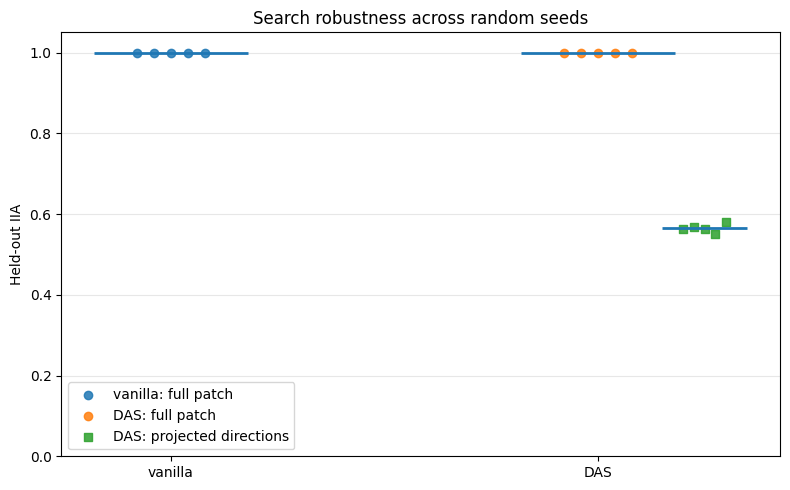

method,das,vanilla
site,,
"(0, 8)",0.0,0.0
"(0, 9)",1.0,0.0
"(1, 8)",0.0,0.0
"(1, 9)",1.0,0.0
"(2, 8)",0.0,0.0
"(2, 9)",1.0,1.0


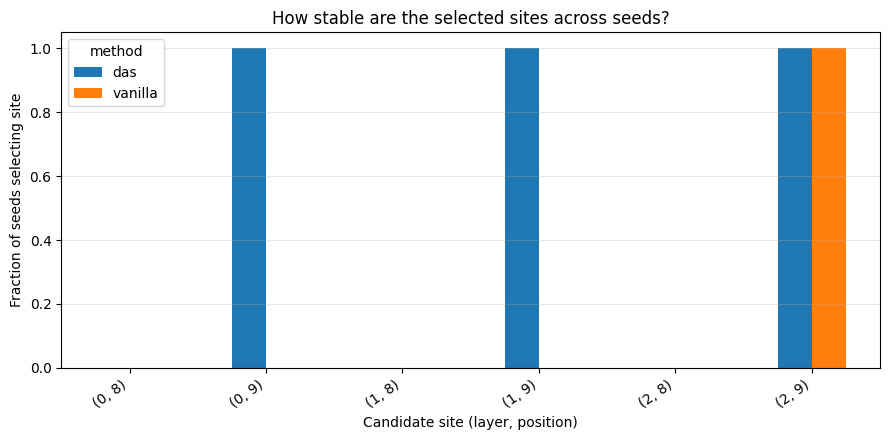

Across-seed summary:


,method,full_patch_mean,full_patch_std,projected_DAS_mean,projected_DAS_std,mean_selected_sites
0,DAS,1.0,0.0,0.564667,0.010698,3.0
1,vanilla,1.0,0.0,NaN,NaN,1.0


In [15]:
from itertools import combinations
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import random
import torch

# ----------------------------
# User controls for this section
# ----------------------------
ABLATION_QUERY_SITES = [(0, 9), (1, 9), (2, 9)]
ROBUSTNESS_SEEDS = [11, 22, 33, 44, 55]
ROBUST_VANILLA_STEPS = 250
ROBUST_DAS_STEPS = 1000
ROBUST_RANDOM_TRIALS = 30

# Ensure all follow-up comparisons use the same original candidate universe.
CANDIDATES = list(ALL_SEARCH_NODES)
ORIGINAL_CANDIDATES = list(ALL_SEARCH_NODES)

# ----------------------------
# A. Single-site and pairwise ablations
# ----------------------------
ablation_sets = []
for r in range(1, len(ABLATION_QUERY_SITES) + 1):
    ablation_sets.extend(combinations(ABLATION_QUERY_SITES, r))

ablation_rows = []
for subset in ablation_sets:
    subset = list(subset)
    full_iia = iia_score(heldout_pairs, subset)
    # Random comparison uses the same number of sites, sampled from the full candidate universe.
    rmean, rstd, _ = random_control(
        heldout_pairs, len(subset), trials=ROBUST_RANDOM_TRIALS, seed=1000 + len(subset)
    )
    ablation_rows.append({
        "sites": str(subset),
        "n_sites": len(subset),
        "full_patch_heldout_iia": full_iia,
        "random_full_patch_mean": rmean,
        "random_full_patch_std": rstd,
    })

ablation_df = pd.DataFrame(ablation_rows)
print("Single-site and pairwise ablations (full activation replacement):")
display(ablation_df)

# If the original DAS run's learned directions are still in memory, evaluate its projected
# intervention on the same subsets. Directions are indexed against ORIGINAL_CANDIDATES.
# If variables are unavailable in a fresh kernel, this section skips this optional column.
try:
    projected_scores = []
    for subset in ablation_sets:
        projected_scores.append(
            das_projected_iia_score(heldout_pairs, list(subset), das_dirs)
        )
    ablation_df["DAS_projected_heldout_iia"] = projected_scores
    print("Added projected-DAS scores using the previously trained das_dirs.")
except (NameError, IndexError, KeyError, RuntimeError) as e:
    print("Projected-DAS ablations skipped; run the original DAS training cell first.", repr(e))

# Plot ablation performance. Each bar is a distinct site subset.
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(ablation_df))
ax.bar(x - 0.2, ablation_df["full_patch_heldout_iia"], width=0.4,
       label="Selected subset: full patch")
ax.bar(x + 0.2, ablation_df["random_full_patch_mean"], width=0.4,
       yerr=ablation_df["random_full_patch_std"], capsize=3,
       label="Random full-patch mean ± SD")
if "DAS_projected_heldout_iia" in ablation_df:
    ax.plot(x, ablation_df["DAS_projected_heldout_iia"], "D--",
            label="DAS projected directions")
ax.set_xticks(x)
ax.set_xticklabels(ablation_df["sites"], rotation=35, ha="right")
ax.set_ylabel("Held-out IIA")
ax.set_ylim(0, 1.05)
ax.set_title("Single-site and pairwise query-token ablations")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# ----------------------------
# B. Multi-seed robustness of the search itself
# ----------------------------
CANDIDATES = list(ORIGINAL_CANDIDATES)
seed_rows = []
seed_selected = {"vanilla": [], "das": []}

for seed in ROBUSTNESS_SEEDS:
    print(f"\n=== Multi-seed search, seed={seed} ===")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    v_nodes, v_probs = vanilla_alignment_search(
        search_pairs, steps=ROBUST_VANILLA_STEPS
    )
    v_iia = iia_score(heldout_pairs, v_nodes)
    v_rmean, v_rstd, _ = random_control(
        heldout_pairs, len(v_nodes), trials=ROBUST_RANDOM_TRIALS, seed=seed + 5000
    )
    seed_selected["vanilla"].append(list(v_nodes))
    seed_rows.append({
        "method": "vanilla", "seed": seed, "selected_sites": str(v_nodes),
        "n_selected": len(v_nodes), "heldout_full_patch_iia": v_iia,
        "heldout_projected_iia": np.nan,
        "random_full_patch_mean": v_rmean, "random_full_patch_std": v_rstd,
    })
    print(f"vanilla: sites={v_nodes}; held-out IIA={v_iia:.3f}; random={v_rmean:.3f}±{v_rstd:.3f}")

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    d_nodes, d_probs, d_dirs = das_alignment_search(
        search_pairs, steps=ROBUST_DAS_STEPS
    )
    d_full_iia = iia_score(heldout_pairs, d_nodes)
    d_proj_iia = das_projected_iia_score(heldout_pairs, d_nodes, d_dirs)
    d_rmean, d_rstd, _ = random_control(
        heldout_pairs, len(d_nodes), trials=ROBUST_RANDOM_TRIALS, seed=seed + 6000
    )
    seed_selected["das"].append(list(d_nodes))
    seed_rows.append({
        "method": "DAS", "seed": seed, "selected_sites": str(d_nodes),
        "n_selected": len(d_nodes), "heldout_full_patch_iia": d_full_iia,
        "heldout_projected_iia": d_proj_iia,
        "random_full_patch_mean": d_rmean, "random_full_patch_std": d_rstd,
    })
    print(
        f"DAS: sites={d_nodes}; full-patch IIA={d_full_iia:.3f}; "
        f"projected IIA={d_proj_iia:.3f}; random={d_rmean:.3f}±{d_rstd:.3f}"
    )

seed_df = pd.DataFrame(seed_rows)
print("Multi-seed results:")
display(seed_df)

# Plot multi-seed held-out IIA. DAS has two distinct metrics.
fig, ax = plt.subplots(figsize=(8, 5))
methods = ["vanilla", "DAS"]
for i, method in enumerate(methods):
    frame = seed_df[seed_df["method"] == method]
    vals = frame["heldout_full_patch_iia"].to_numpy()
    xvals = np.full(len(vals), i, dtype=float) + np.linspace(-0.08, 0.08, len(vals))
    ax.scatter(xvals, vals, label=f"{method}: full patch", alpha=0.85)
    ax.hlines(np.mean(vals), i - 0.18, i + 0.18, linewidth=2)
    if method == "DAS":
        pvals = frame["heldout_projected_iia"].to_numpy()
        xp = np.full(len(pvals), i + 0.25) + np.linspace(-0.05, 0.05, len(pvals))
        ax.scatter(xp, pvals, marker="s", label="DAS: projected directions", alpha=0.85)
        ax.hlines(np.mean(pvals), i + 0.15, i + 0.35, linewidth=2)
ax.set_xticks([0, 1])
ax.set_xticklabels(methods)
ax.set_ylabel("Held-out IIA")
ax.set_ylim(0, 1.05)
ax.set_title("Search robustness across random seeds")
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Plot site selection frequency across seeds.
site_counts = []
for method, runs in seed_selected.items():
    counts = Counter(site for selected in runs for site in selected)
    for site in ORIGINAL_CANDIDATES:
        site_counts.append({
            "method": method,
            "site": str(site),
            "selection_frequency": counts[site] / len(runs),
        })
freq_df = pd.DataFrame(site_counts)
freq_pivot = freq_df.pivot(index="site", columns="method", values="selection_frequency").fillna(0)
display(freq_pivot)

ax = freq_pivot.plot(kind="bar", figsize=(9, 4.5))
ax.set_ylabel("Fraction of seeds selecting site")
ax.set_xlabel("Candidate site (layer, position)")
ax.set_ylim(0, 1.05)
ax.set_title("How stable are the selected sites across seeds?")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Summary statistics for held-out IIA across seeds.
summary_rows = []
for method, frame in seed_df.groupby("method"):
    summary_rows.append({
        "method": method,
        "full_patch_mean": frame["heldout_full_patch_iia"].mean(),
        "full_patch_std": frame["heldout_full_patch_iia"].std(ddof=1),
        "projected_DAS_mean": frame["heldout_projected_iia"].mean() if method == "DAS" else np.nan,
        "projected_DAS_std": frame["heldout_projected_iia"].std(ddof=1) if method == "DAS" else np.nan,
        "mean_selected_sites": frame["n_selected"].mean(),
    })
print("Across-seed summary:")
display(pd.DataFrame(summary_rows))